# 09 — Spatial Validation

## Objective

This notebook evaluates the spatial characteristics of the 30 m LST downscaled products using additional spatial validation measures.

The analysis is designed to determine whether Random Forest and XGBoost preserve meaningful spatial structure in the downscaled LST products rather than simply producing smoother temperature distributions.

### Analyses

1. Moran's I — spatial autocorrelation
2. Variogram analysis — spatial dependence across distance
3. Hotspot preservation — spatial agreement of thermal extremes
4. Thermal variability and smoothing assessment

## 1. Moran's I — Spatial Autocorrelation

In [154]:
!pip install libpysal esda


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [155]:
import numpy as np
from pathlib import Path
import rasterio
from libpysal.weights import lat2W
from esda.moran import Moran

In [156]:
PROJECT_DIR = Path(r"D:\Projects\GeoAI-LST-Downscaling")
FINE_DIR = PROJECT_DIR / "data" / "processed" / "lucknow" / "fine"
COARSE_DIR = PROJECT_DIR / "data" / "processed" / "lucknow" / "coarse"
DOWNSCALED_DIR = PROJECT_DIR / "data" / "processed" / "lucknow" / "downscaled"

reference_path = FINE_DIR/ "predictors" / "lst_clean_lucknow.tif"
tsharp_path = DOWNSCALED_DIR / "tsharp_lst_30m_lucknow.tif"
rf_path = DOWNSCALED_DIR / "rf_lst_30m_lucknow.tif"
xgb_path = DOWNSCALED_DIR / "xgb_lst_30m_lucknow.tif"

In [157]:




def read_raster(path):
    path = Path(path)

    if not path.exists():
        raise FileNotFoundError(f"Raster not found: {path}")

    with rasterio.open(path) as src:
        data = src.read(1).astype(np.float64)
        profile = src.profile.copy()
        nodata = src.nodata

    # Convert NoData values to NaN
    if nodata is not None and not np.isnan(nodata):
        data[data == nodata] = np.nan

    return data, profile, nodata

reference, ref_profile, ref_nodata = read_raster(reference_path)
tsharp, tsharp_profile, tsharp_nodata = read_raster(tsharp_path)
rf, rf_profile, rf_nodata = read_raster(rf_path)
xgb, xgb_profile, xgb_nodata = read_raster(xgb_path)

print("Reference:", reference.shape)
print("TsHARP:", tsharp.shape)
print("RF:", rf.shape)
print("XGBoost:", xgb.shape)

Reference: (703, 762)
TsHARP: (702, 762)
RF: (703, 762)
XGBoost: (703, 762)


In [158]:
print("Reference shape:", reference.shape)
print("TsHARP shape:", tsharp.shape)
print("RF shape:", rf.shape)
print("XGBoost shape:", xgb.shape)

print("Reference resolution:", ref_profile["transform"].a, abs(ref_profile["transform"].e))
print("TsHARP resolution:", tsharp_profile["transform"].a, abs(tsharp_profile["transform"].e))
print("RF resolution:", rf_profile["transform"].a, abs(rf_profile["transform"].e))
print("XGBoost resolution:", xgb_profile["transform"].a, abs(xgb_profile["transform"].e))



Reference shape: (703, 762)
TsHARP shape: (702, 762)
RF shape: (703, 762)
XGBoost shape: (703, 762)
Reference resolution: 30.0 30.0
TsHARP resolution: 30.0 30.0
RF resolution: 30.0 30.0
XGBoost resolution: 30.0 30.0


In [159]:
rasters = {
    "Reference": (reference, ref_profile),
    "TsHARP": (tsharp, tsharp_profile),
    "Random Forest": (rf, rf_profile),
    "XGBoost": (xgb, xgb_profile),
}

for name, (data, profile) in rasters.items():
    print(f"\n{name}")
    print("Shape:", data.shape)
    print("Transform:", profile["transform"])
    print("Bounds:", rasterio.transform.array_bounds(
        data.shape[0],
        data.shape[1],
        profile["transform"]
    ))


Reference
Shape: (703, 762)
Transform: | 30.00, 0.00, 483225.00|
| 0.00,-30.00, 2979165.00|
| 0.00, 0.00, 1.00|
Bounds: (483225.0, 2958075.0, 506085.0, 2979165.0)

TsHARP
Shape: (702, 762)
Transform: | 30.00, 0.00, 483225.00|
| 0.00,-30.00, 2979165.00|
| 0.00, 0.00, 1.00|
Bounds: (483225.0, 2958105.0, 506085.0, 2979165.0)

Random Forest
Shape: (703, 762)
Transform: | 30.00, 0.00, 483225.00|
| 0.00,-30.00, 2979165.00|
| 0.00, 0.00, 1.00|
Bounds: (483225.0, 2958075.0, 506085.0, 2979165.0)

XGBoost
Shape: (703, 762)
Transform: | 30.00, 0.00, 483225.00|
| 0.00,-30.00, 2979165.00|
| 0.00, 0.00, 1.00|
Bounds: (483225.0, 2958075.0, 506085.0, 2979165.0)


In [160]:
print("\nCRS:")
for name, (_, profile) in rasters.items():
    print(name, profile["crs"])

print("\nResolution:")
for name, (_, profile) in rasters.items():
    print(
        name,
        profile["transform"].a,
        abs(profile["transform"].e)
    )


CRS:
Reference EPSG:32644
TsHARP EPSG:32644
Random Forest EPSG:32644
XGBoost EPSG:32644

Resolution:
Reference 30.0 30.0
TsHARP 30.0 30.0
Random Forest 30.0 30.0
XGBoost 30.0 30.0


In [161]:
# Crop all rasters to the common spatial extent
common_rows = min(
    reference.shape[0],
    tsharp.shape[0],
    rf.shape[0],
    xgb.shape[0]
)

common_cols = min(
    reference.shape[1],
    tsharp.shape[1],
    rf.shape[1],
    xgb.shape[1]
)

reference_common = reference[:common_rows, :common_cols]
tsharp_common = tsharp[:common_rows, :common_cols]
rf_common = rf[:common_rows, :common_cols]
xgb_common = xgb[:common_rows, :common_cols]

print("Reference:", reference_common.shape)
print("TsHARP:", tsharp_common.shape)
print("RF:", rf_common.shape)
print("XGBoost:", xgb_common.shape)

Reference: (702, 762)
TsHARP: (702, 762)
RF: (702, 762)
XGBoost: (702, 762)


In [162]:
valid_mask = (
    np.isfinite(reference_common) &
    np.isfinite(tsharp_common) &
    np.isfinite(rf_common) &
    np.isfinite(xgb_common)
)

print("Total pixels:", valid_mask.size)
print("Valid pixels:", valid_mask.sum())
print("Invalid pixels:", (~valid_mask).sum())

Total pixels: 534924
Valid pixels: 314648
Invalid pixels: 220276


In [163]:
reference_values = reference_common[valid_mask]
tsharp_values = tsharp_common[valid_mask]
rf_values = rf_common[valid_mask]
xgb_values = xgb_common[valid_mask]

print("Number of valid pixels:", len(reference_values))

Number of valid pixels: 314648


In [164]:
from libpysal.weights import lat2W

rows, cols = reference.shape

# Rook contiguity: edge-sharing neighbours
w = lat2W(rows, cols, rook=True)
# Create rook-contiguity weights for the complete raster grid
w_full = lat2W(rows, cols, rook=True)
print("Number of spatial units:", w.n)
print("Number of neighbours for first pixel:", len(w.neighbors[0]))

Number of spatial units: 535686
Number of neighbours for first pixel: 2


In [165]:
print("Total pixels:", reference.size)
print("Valid pixels:", valid_mask.sum())
print("Invalid pixels:", (~valid_mask).sum())

Total pixels: 535686
Valid pixels: 314648
Invalid pixels: 220276


In [166]:
valid_flat = valid_mask.flatten()

valid_indices = np.where(valid_flat)[0]

print("Valid spatial units:", len(valid_indices))

Valid spatial units: 314648


In [167]:
from libpysal.weights import W

valid_indices = np.where(valid_flat)[0]

# Map original raster index -> new index
index_map = {
    old_idx: new_idx
    for new_idx, old_idx in enumerate(valid_indices)
}

neighbors = {}
weights = {}

for old_idx in valid_indices:
    new_idx = index_map[old_idx]

    # Original neighbours from the full raster
    old_neighbors = w_full.neighbors[old_idx]

    # Keep only neighbours that are also valid
    valid_neighbors = [
        n for n in old_neighbors
        if n in index_map
    ]

    neighbors[new_idx] = [
        index_map[n] for n in valid_neighbors
    ]

    weights[new_idx] = [1.0] * len(valid_neighbors)

# Create the reduced spatial weights object
w = W(neighbors, weights)

print("Original spatial units:", w_full.n)
print("Valid spatial units:", len(valid_indices))
print("Spatial units in new weights:", w.n)

Original spatial units: 535686
Valid spatial units: 314648
Spatial units in new weights: 314648


In [168]:
print("Number of islands:", w.n_components)
print("Average neighbours:", np.mean(list(map(len, w.neighbors.values()))))

Number of islands: 1
Average neighbours: 3.9876941852482775


In [169]:
reference_values = reference_common[valid_mask]
tsharp_values = tsharp_common[valid_mask]
rf_values = rf_common[valid_mask]
xgb_values = xgb_common[valid_mask]

In [170]:
from esda.moran import Moran

# Calculate Moran's I
moran_reference = Moran(
    reference_values,
    w,
    permutations=999
)

moran_tsharp = Moran(
    tsharp_values,
    w,
    permutations=999
)

moran_rf = Moran(
    rf_values,
    w,
    permutations=999
)

moran_xgb = Moran(
    xgb_values,
    w,
    permutations=999
)

In [171]:
print("Reference 30 m")
print("Moran's I:", moran_reference.I)
print("Expected I:", moran_reference.EI)
print("Z-score:", moran_reference.z_sim)
print("Permutation p-value:", moran_reference.p_sim)

print("\nTsHARP 30 m")
print("Moran's I:", moran_tsharp.I)
print("Expected I:", moran_tsharp.EI)
print("Z-score:", moran_tsharp.z_sim)
print("Permutation p-value:", moran_tsharp.p_sim)

print("\nRandom Forest 30 m")
print("Moran's I:", moran_rf.I)
print("Expected I:", moran_rf.EI)
print("Z-score:", moran_rf.z_sim)
print("Permutation p-value:", moran_rf.p_sim)

print("\nXGBoost 30 m")
print("Moran's I:", moran_xgb.I)
print("Expected I:", moran_xgb.EI)
print("Z-score:", moran_xgb.z_sim)
print("Permutation p-value:", moran_xgb.p_sim)

Reference 30 m
Moran's I: 0.9842988877260397
Expected I: -3.178164736990977e-06
Z-score: 782.4086512540384
Permutation p-value: 0.001

TsHARP 30 m
Moran's I: 0.9438660487743782
Expected I: -3.178164736990977e-06
Z-score: 791.5763002115966
Permutation p-value: 0.001

Random Forest 30 m
Moran's I: 0.8138341868665738
Expected I: -3.178164736990977e-06
Z-score: 653.3188542925
Permutation p-value: 0.001

XGBoost 30 m
Moran's I: 0.828310805810523
Expected I: -3.178164736990977e-06
Z-score: 642.285552519196
Permutation p-value: 0.001


In [172]:
import pandas as pd

RESULTS_DIR = PROJECT_DIR / "results" / "spatial_validation"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

moran_results = {
    "Reference": {
        "Moran_I": moran_reference.I,
        "Expected_I": moran_reference.EI,
        "Z_score": moran_reference.z_sim,
        "p_value": moran_reference.p_sim,
    },
    "TsHARP": {
        "Moran_I": moran_tsharp.I,
        "Expected_I": moran_tsharp.EI,
        "Z_score": moran_tsharp.z_sim,
        "p_value": moran_tsharp.p_sim,
    },
    "Random Forest": {
        "Moran_I": moran_rf.I,
        "Expected_I": moran_rf.EI,
        "Z_score": moran_rf.z_sim,
        "p_value": moran_rf.p_sim,
    },
    "XGBoost": {
        "Moran_I": moran_xgb.I,
        "Expected_I": moran_xgb.EI,
        "Z_score": moran_xgb.z_sim,
        "p_value": moran_xgb.p_sim,
    },
}

moran_df = pd.DataFrame.from_dict(moran_results, orient="index")

moran_output = RESULTS_DIR / "moran_i_results.csv"
moran_df.to_csv(moran_output, index_label="Method")

print(f"Moran's I results saved to:\n{moran_output}")

moran_df

Moran's I results saved to:
D:\Projects\GeoAI-LST-Downscaling\results\spatial_validation\moran_i_results.csv


,Moran_I,Expected_I,Z_score,p_value
Reference,0.984299,-0.000003,782.408651,0.001
TsHARP,0.943866,-0.000003,791.576300,0.001
Random Forest,0.813834,-0.000003,653.318854,0.001
XGBoost,0.828311,-0.000003,642.285553,0.001


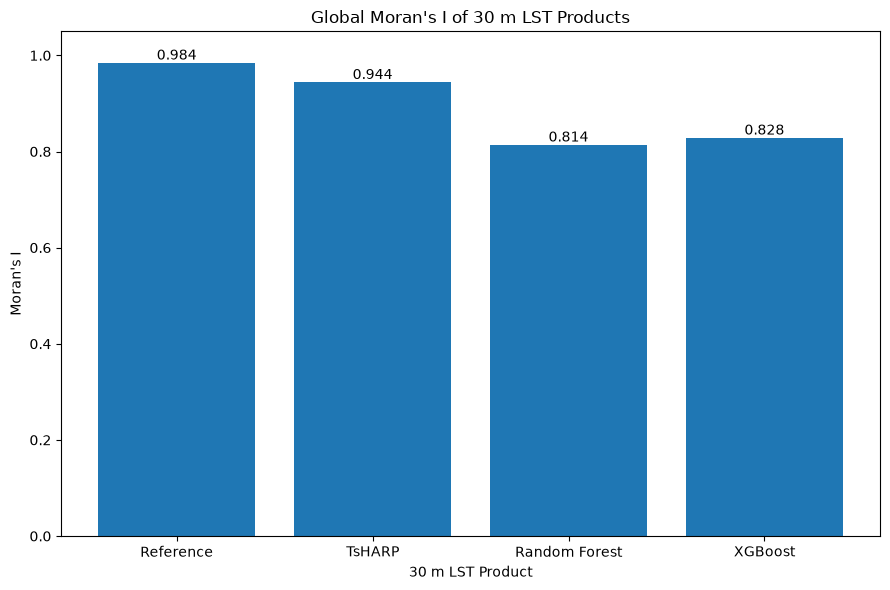

<Figure size 640x480 with 0 Axes>

In [173]:
import matplotlib.pyplot as plt
import numpy as np
FIGURES_DIR = PROJECT_DIR / "figures" / "lucknow" / "notebook_9"

models = [
    "Reference",
    "TsHARP",
    "Random Forest",
    "XGBoost"
]

moran_values = [
    moran_reference.I,
    moran_tsharp.I,
    moran_rf.I,
    moran_xgb.I
]

plt.figure(figsize=(9, 6))

bars = plt.bar(models, moran_values)

plt.ylabel("Moran's I")
plt.xlabel("30 m LST Product")
plt.title("Global Moran's I of 30 m LST Products")

# Add values above bars
for bar, value in zip(bars, moran_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.3f}",
        ha="center",
        va="bottom"
    )

plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()
plt.savefig(FIGURES_DIR/ "Moran's_I_30m_LST")

## 2. Variogram - Difference in Temperatures of Pixels as the distance increases

In [174]:
!pip install scikit-gstat


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [175]:
from skgstat import Variogram

In [176]:
print("Reference:", reference_common.shape)
print("TsHARP:", tsharp_common.shape)
print("RF:", rf_common.shape)
print("XGBoost:", xgb_common.shape)

print("Common valid pixels:", valid_mask.sum())

Reference: (702, 762)
TsHARP: (702, 762)
RF: (702, 762)
XGBoost: (702, 762)
Common valid pixels: 314648


In [177]:
# Get coordinates of common valid pixels
valid_coords = np.column_stack(np.where(valid_mask))

print("Total common valid pixels:", len(valid_coords))

# Reproducible sample
rng = np.random.default_rng(42)

n_samples = min(5000, len(valid_coords))

sample_idx = rng.choice(
    len(valid_coords),
    size=n_samples,
    replace=False
)

sample_coords = valid_coords[sample_idx]

print("Sampled pixels:", len(sample_coords))

Total common valid pixels: 314648
Sampled pixels: 5000


In [178]:
ref_values = reference_common[
    sample_coords[:, 0],
    sample_coords[:, 1]
]

tsharp_values = tsharp_common[
    sample_coords[:, 0],
    sample_coords[:, 1]
]

rf_values = rf_common[
    sample_coords[:, 0],
    sample_coords[:, 1]
]

xgb_values = xgb_common[
    sample_coords[:, 0],
    sample_coords[:, 1]
]

In [179]:
sample_coords_m = sample_coords.astype(float) * 30

In [180]:
V_ref = Variogram(
    sample_coords_m,
    ref_values,
    n_lags=30,
    maxlag=3000,
    normalize=False,
    model='spherical'
)

V_tsharp = Variogram(
    sample_coords_m,
    tsharp_values,
    n_lags=30,
    maxlag=3000,
    normalize=False,
    model='spherical'
)

V_rf = Variogram(
    sample_coords_m,
    rf_values,
    n_lags=30,
    maxlag=3000,
    normalize=False,
    model='spherical'
)

V_xgb = Variogram(
    sample_coords_m,
    xgb_values,
    n_lags=30,
    maxlag=3000,
    normalize=False,
    model='spherical'
)

In [181]:
print("Reference:")
print("Effective range:", V_ref.parameters[0])
print("Sill:", V_ref.parameters[1])
print("Nugget:", V_ref.parameters[2])

print("\nTsHARP:")
print("Effective range:", V_tsharp.parameters[0])
print("Sill:", V_tsharp.parameters[1])
print("Nugget:", V_tsharp.parameters[2])

print("\nRandom Forest:")
print("Effective range:", V_rf.parameters[0])
print("Sill:", V_rf.parameters[1])
print("Nugget:", V_rf.parameters[2])

print("\nXGBoost:")
print("Effective range:", V_xgb.parameters[0])
print("Sill:", V_xgb.parameters[1])
print("Nugget:", V_xgb.parameters[2])

Reference:
Effective range: 1325.7110044877159
Sill: 1.5013468299089163
Nugget: 0

TsHARP:
Effective range: 1189.3927716187923
Sill: 1.576230121373448
Nugget: 0

Random Forest:
Effective range: 619.597707663426
Sill: 1.545354596277274
Nugget: 0

XGBoost:
Effective range: 643.6450081167225
Sill: 1.4816470682911704
Nugget: 0


In [182]:
variogram_results = {
    "Reference": V_ref,
    "TsHARP": V_tsharp,
    "Random Forest": V_rf,
    "XGBoost": V_xgb,
}

# Save fitted variogram parameters
variogram_summary = pd.DataFrame([
    {
        "Method": name,
        "Effective_range_m": variogram.parameters[0],
        "Sill": variogram.parameters[1],
        "Nugget": variogram.parameters[2],
    }
    for name, variogram in variogram_results.items()
])

variogram_summary_path = RESULTS_DIR / "variogram_results.csv"
variogram_summary.to_csv(variogram_summary_path, index=False)


print(f"Saved summary to: {variogram_summary_path}")

Saved summary to: D:\Projects\GeoAI-LST-Downscaling\results\spatial_validation\variogram_results.csv


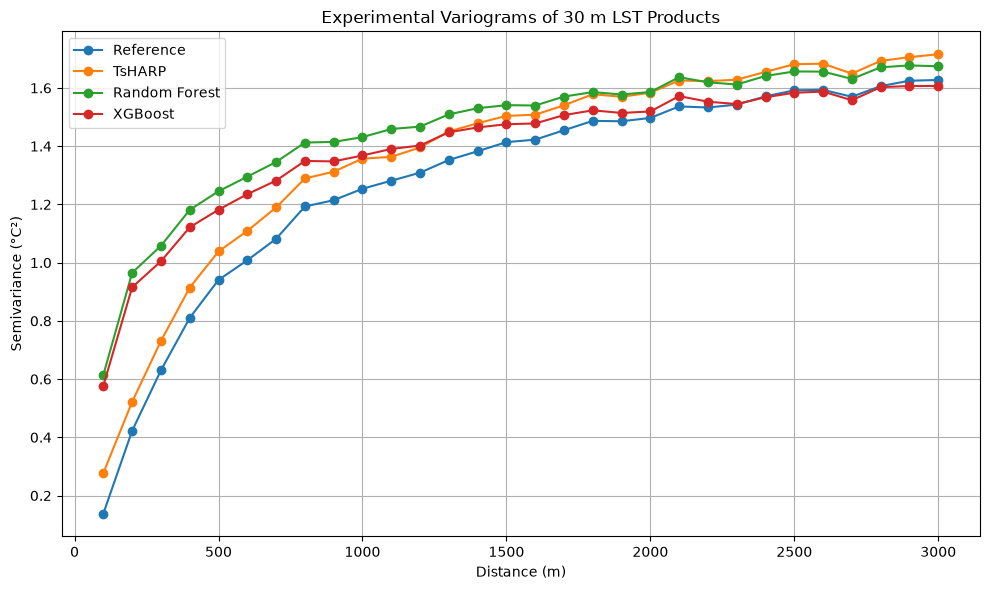

<Figure size 640x480 with 0 Axes>

In [183]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))

plt.plot(
    V_ref.bins,
    V_ref.experimental,
    marker='o',
    label='Reference'
)

plt.plot(
    V_tsharp.bins,
    V_tsharp.experimental,
    marker='o',
    label='TsHARP'
)

plt.plot(
    V_rf.bins,
    V_rf.experimental,
    marker='o',
    label='Random Forest'
)

plt.plot(
    V_xgb.bins,
    V_xgb.experimental,
    marker='o',
    label='XGBoost'
)

plt.xlabel("Distance (m)")
plt.ylabel("Semivariance (°C²)")
plt.title("Experimental Variograms of 30 m LST Products")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
plt.savefig(FIGURES_DIR/"Variogram_30m_LST")

## 3. Hotspot Preservation Check

In [184]:
# Flatten only the common valid pixels
ref_values = reference_common[valid_mask]
tsharp_values = tsharp_common[valid_mask]
rf_values = rf_common[valid_mask]
xgb_values = xgb_common[valid_mask]

print("Number of valid pixels:", len(ref_values))

Number of valid pixels: 314648


In [185]:
# Reference thresholds
hot_threshold = np.percentile(ref_values, 90)
cold_threshold = np.percentile(ref_values, 10)

print("Reference hot threshold (90th percentile):", hot_threshold)
print("Reference cold threshold (10th percentile):", cold_threshold)

Reference hot threshold (90th percentile): 40.75921630859375
Reference cold threshold (10th percentile): 37.409576416015625


In [186]:
# Reference masks
ref_hot = ref_values >= hot_threshold
ref_cold = ref_values <= cold_threshold

# Model masks using the SAME reference thresholds
tsharp_hot = tsharp_values >= hot_threshold
rf_hot = rf_values >= hot_threshold
xgb_hot = xgb_values >= hot_threshold

tsharp_cold = tsharp_values <= cold_threshold
rf_cold = rf_values <= cold_threshold
xgb_cold = xgb_values <= cold_threshold

In [187]:
from sklearn.metrics import precision_score, recall_score, f1_score, jaccard_score

def hotspot_metrics(reference_mask, predicted_mask):
    precision = precision_score(
        reference_mask,
        predicted_mask,
        zero_division=0
    )

    recall = recall_score(
        reference_mask,
        predicted_mask,
        zero_division=0
    )

    f1 = f1_score(
        reference_mask,
        predicted_mask,
        zero_division=0
    )

    iou = jaccard_score(
        reference_mask,
        predicted_mask,
        zero_division=0
    )

    return precision, recall, f1, iou

In [188]:
hot_results = {}

for name, prediction in [
    ("TsHARP", tsharp_hot),
    ("Random Forest", rf_hot),
    ("XGBoost", xgb_hot)
]:
    
    precision, recall, f1, iou = hotspot_metrics(
        ref_hot,
        prediction
    )
    
    hot_results[name] = {
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "IoU": iou
    }

hot_results

{'TsHARP': {'Precision': 0.7940275190770895,
  'Recall': 0.8383822363203807,
  'F1': 0.8156022897347672,
  'IoU': 0.6886219744144239},
 'Random Forest': {'Precision': 0.5067920585161965,
  'Recall': 0.4153846153846154,
  'F1': 0.45655812007530855,
  'IoU': 0.2958051909914387},
 'XGBoost': {'Precision': 0.5218123496391339,
  'Recall': 0.4128152260111023,
  'F1': 0.4609581156468609,
  'IoU': 0.2995097926399853}}

In [189]:
cold_results = {}

for name, prediction in [
    ("TsHARP", tsharp_cold),
    ("Random Forest", rf_cold),
    ("XGBoost", xgb_cold)
]:
    
    precision, recall, f1, iou = hotspot_metrics(
        ref_cold,
        prediction
    )
    
    cold_results[name] = {
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "IoU": iou
    }

cold_results

{'TsHARP': {'Precision': 0.799319118437556,
  'Recall': 0.8502811398074908,
  'F1': 0.8240129300392519,
  'IoU': 0.700698971177256},
 'Random Forest': {'Precision': 0.6686699247127196,
  'Recall': 0.6432860001906032,
  'F1': 0.6557323964185677,
  'IoU': 0.48779900272203885},
 'XGBoost': {'Precision': 0.6807124681933843,
  'Recall': 0.6373772991518155,
  'F1': 0.6583325130426223,
  'IoU': 0.49068231841526044}}

In [190]:
hot_df = pd.DataFrame(hot_results).T
hot_df.index.name = "Model"

cold_df = pd.DataFrame(cold_results).T
cold_df.index.name = "Model"

print("HOTSPOT PRESERVATION")
display(hot_df.round(4))

print("\nCOLDSPOT PRESERVATION")
display(cold_df.round(4))

hotspot_coldspot_df = pd.concat(
    [
        hot_df.add_prefix("Hotspot_"),
        cold_df.add_prefix("Coldspot_")
    ],
    axis=1
)

hotspot_coldspot_df.index.name = "Model"

hotspot_coldspot_df_path = RESULTS_DIR / "hotspot_coldspot_results.csv"
hotspot_coldspot_df.to_csv(hotspot_coldspot_df_path)

print("Saved result to:", hotspot_coldspot_df_path)

HOTSPOT PRESERVATION


,Precision,Recall,F1,IoU
Model,,,,
TsHARP,0.7940,0.8384,0.8156,0.6886
Random Forest,0.5068,0.4154,0.4566,0.2958
XGBoost,0.5218,0.4128,0.4610,0.2995



COLDSPOT PRESERVATION


,Precision,Recall,F1,IoU
Model,,,,
TsHARP,0.7993,0.8503,0.8240,0.7007
Random Forest,0.6687,0.6433,0.6557,0.4878
XGBoost,0.6807,0.6374,0.6583,0.4907


Saved result to: D:\Projects\GeoAI-LST-Downscaling\results\spatial_validation\hotspot_coldspot_results.csv


In [191]:
count_results = []

for name, hot_mask, cold_mask in [
    ("Reference", ref_hot, ref_cold),
    ("TsHARP", tsharp_hot, tsharp_cold),
    ("Random Forest", rf_hot, rf_cold),
    ("XGBoost", xgb_hot, xgb_cold)
]:
    
    count_results.append({
        "Model": name,
        "Hotspot_pixels": int(hot_mask.sum()),
        "Coldspot_pixels": int(cold_mask.sum())
    })

count_df = pd.DataFrame(count_results)

display(count_df)
count_df_path = RESULTS_DIR/ "hotspots_coldspots_count.csv"
count_df.to_csv(count_df_path, index = False)

print("Saved csv file to: ", count_df_path)


,Model,Hotspot_pixels,Coldspot_pixels
0,Reference,31525,31479
1,TsHARP,33286,33486
2,Random Forest,25839,30284
3,XGBoost,24940,29475


Saved csv file to:  D:\Projects\GeoAI-LST-Downscaling\results\spatial_validation\hotspots_coldspots_count.csv


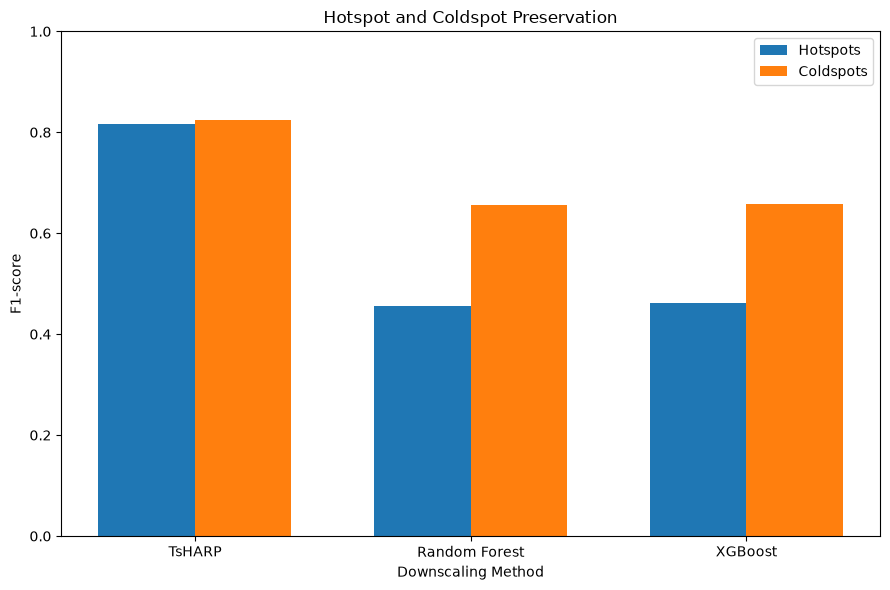

<Figure size 640x480 with 0 Axes>

In [192]:
models = list(hot_results.keys())

hot_f1 = [
    hot_results[m]["F1"]
    for m in models
]

cold_f1 = [
    cold_results[m]["F1"]
    for m in models
]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(9, 6))

plt.bar(
    x - width/2,
    hot_f1,
    width,
    label="Hotspots"
)

plt.bar(
    x + width/2,
    cold_f1,
    width,
    label="Coldspots"
)

plt.xticks(x, models)
plt.ylabel("F1-score")
plt.xlabel("Downscaling Method")
plt.title("Hotspot and Coldspot Preservation")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()
plt.savefig(FIGURES_DIR/ "Hotspot_Preservation")

## 4. Smoothing Analysis

In [193]:
for name, data in {
    "Reference": reference_valid,
    "TsHARP": tsharp_valid,
    "Random Forest": rf_valid,
    "XGBoost": xgb_valid
}.items():

    print(f"\n{name}")
    print("Length:", len(data))
    print("Finite:", np.isfinite(data).sum())
    print("NaN:", np.isnan(data).sum())
    print("Min:", np.nanmin(data))
    print("Max:", np.nanmax(data))
    print("Mean:", np.nanmean(data))


Reference
Length: 314648
Finite: 314648
NaN: 0
Min: 32.23809814453125
Max: 45.20947265625
Mean: 39.17652813913208

TsHARP
Length: 314648
Finite: 314648
NaN: 0
Min: 30.975879669189453
Max: 45.252349853515625
Mean: 39.17654878859001

Random Forest
Length: 314648
Finite: 314648
NaN: 0
Min: 33.0905647277832
Max: 44.17073440551758
Mean: 39.22078657754029

XGBoost
Length: 314648
Finite: 314648
NaN: 0
Min: 33.60115051269531
Max: 44.46719741821289
Mean: 39.210472017618315


In [194]:
print("reference_common shape:", reference_common.shape)
print("tsharp_common shape:", tsharp_common.shape)
print("rf_common shape:", rf_common.shape)
print("xgb_common shape:", xgb_common.shape)

print("Valid mask shape:", valid_mask.shape)
print("Valid pixels:", valid_mask.sum())

reference_common shape: (702, 762)
tsharp_common shape: (702, 762)
rf_common shape: (702, 762)
xgb_common shape: (702, 762)
Valid mask shape: (702, 762)
Valid pixels: 314648


In [195]:
# Fresh arrays for thermal/smoothing analysis
thermal_reference = reference_common[valid_mask]
thermal_tsharp = tsharp_common[valid_mask]
thermal_rf = rf_common[valid_mask]
thermal_xgb = xgb_common[valid_mask]

for name, data in {
    "Reference": thermal_reference,
    "TsHARP": thermal_tsharp,
    "Random Forest": thermal_rf,
    "XGBoost": thermal_xgb
}.items():

    print(f"\n{name}")
    print("Length:", len(data))
    print("Finite:", np.isfinite(data).sum())
    print("Min:", np.min(data))
    print("Max:", np.max(data))
    print("Mean:", np.mean(data))
    print("Std:", np.std(data))


Reference
Length: 314648
Finite: 314648
Min: 32.23809814453125
Max: 45.20947265625
Mean: 39.17652813913208
Std: 1.508243780344154

TsHARP
Length: 314648
Finite: 314648
Min: 30.975879669189453
Max: 45.252349853515625
Mean: 39.17654878859001
Std: 1.539404460722145

Random Forest
Length: 314648
Finite: 314648
Min: 33.0905647277832
Max: 44.17073440551758
Mean: 39.22078657754029
Std: 1.3530529677204781

XGBoost
Length: 314648
Finite: 314648
Min: 33.60115051269531
Max: 44.46719741821289
Mean: 39.210472017618315
Std: 1.3262938354141771


In [196]:
thermal_results = []

datasets = {
    "Reference": thermal_reference,
    "TsHARP": thermal_tsharp,
    "Random Forest": thermal_rf,
    "XGBoost": thermal_xgb
}

for name, data in datasets.items():

    thermal_results.append({
        "Model": name,
        "Minimum": np.min(data),
        "Maximum": np.max(data),
        "Mean": np.mean(data),
        "Std_Dev": np.std(data),
        "Thermal_Range": np.ptp(data),
        "P5": np.percentile(data, 5),
        "P95": np.percentile(data, 95)
    })

thermal_df = pd.DataFrame(thermal_results)

display(thermal_df.round(3))

,Model,Minimum,Maximum,Mean,Std_Dev,Thermal_Range,P5,P95
0,Reference,32.238,45.209,39.177,1.508,12.971,36.569,41.320
1,TsHARP,30.976,45.252,39.177,1.539,14.276,36.483,41.346
2,Random Forest,33.091,44.171,39.221,1.353,11.080,36.496,41.196
3,XGBoost,33.601,44.467,39.210,1.326,10.866,36.537,41.183


In [197]:
reference_range = np.ptp(thermal_reference)
reference_std = np.std(thermal_reference)

smoothing_results = []

for name, data in datasets.items():

    thermal_range = np.ptp(data)
    std = np.std(data)

    smoothing_results.append({
        "Model": name,
        "Range_Retention_%": (thermal_range / reference_range) * 100,
        "Std_Retention_%": (std / reference_std) * 100
    })

smoothing_df = pd.DataFrame(smoothing_results)

display(smoothing_df.round(2))

,Model,Range_Retention_%,Std_Retention_%
0,Reference,100.00,100.00
1,TsHARP,110.06,102.07
2,Random Forest,85.42,89.71
3,XGBoost,83.77,87.94


In [198]:
thermal_df.to_csv(
    PROJECT_DIR/"results/thermal_validation/thermal_statistics.csv",
    index=False
)

smoothing_df.to_csv(
    PROJECT_DIR/"results/thermal_validation/smoothing_assessment.csv",
    index=False
)

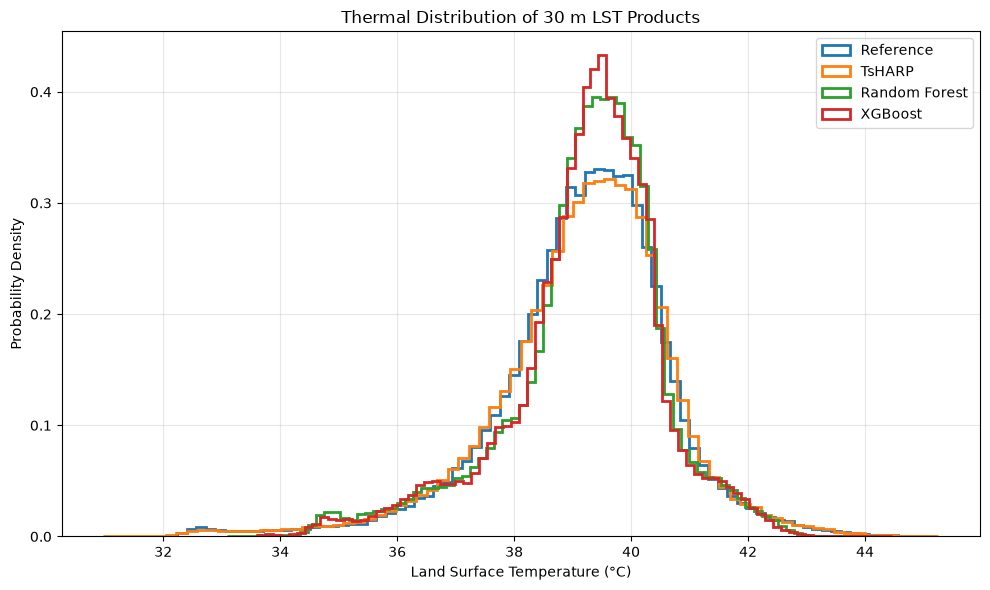

In [199]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.hist(
    thermal_reference,
    bins=80,
    density=True,
    histtype="step",
    linewidth=2,
    label="Reference"
)

plt.hist(
    thermal_tsharp,
    bins=80,
    density=True,
    histtype="step",
    linewidth=2,
    label="TsHARP"
)

plt.hist(
    thermal_rf,
    bins=80,
    density=True,
    histtype="step",
    linewidth=2,
    label="Random Forest"
)

plt.hist(
    thermal_xgb,
    bins=80,
    density=True,
    histtype="step",
    linewidth=2,
    label="XGBoost"
)

plt.xlabel("Land Surface Temperature (°C)")
plt.ylabel("Probability Density")
plt.title("Thermal Distribution of 30 m LST Products")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "Thermal_Distribution_30m_LST",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

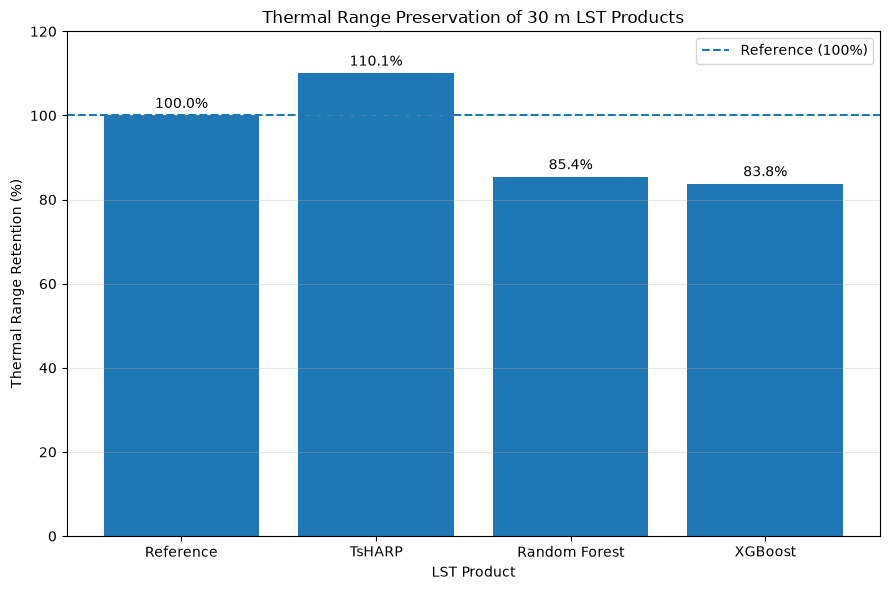

In [200]:
import matplotlib.pyplot as plt

models = smoothing_df["Model"].tolist()
range_retention = smoothing_df["Range_Retention_%"].tolist()

plt.figure(figsize=(9, 6))

bars = plt.bar(
    models,
    range_retention
)

plt.axhline(
    100,
    linestyle="--",
    linewidth=1.5,
    label="Reference (100%)"
)

for bar, value in zip(bars, range_retention):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value:.1f}%",
        ha="center",
        va="bottom"
    )

plt.xlabel("LST Product")
plt.ylabel("Thermal Range Retention (%)")
plt.title("Thermal Range Preservation of 30 m LST Products")
plt.ylim(0, 120)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR/"Thermal_Range_Preservation_30m_LST",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 4. Structural Analysis

In [201]:
!pip install scikit-image


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [202]:
from skimage.metrics import structural_similarity as ssim
import numpy as np
import pandas as pd

In [203]:
ref_struct = reference_common.copy()
tsharp_struct = tsharp_common.copy()
rf_struct = rf_common.copy()
xgb_struct = xgb_common.copy()

reference_mean = np.nanmean(reference_common)

ref_struct[~np.isfinite(ref_struct)] = reference_mean
tsharp_struct[~np.isfinite(tsharp_struct)] = reference_mean
rf_struct[~np.isfinite(rf_struct)] = reference_mean
xgb_struct[~np.isfinite(xgb_struct)] = reference_mean

In [204]:
data_range = (
    np.nanmax(reference_common)
    - np.nanmin(reference_common)
)

ssim_tsharp = ssim(
    ref_struct,
    tsharp_struct,
    data_range=data_range
)

ssim_rf = ssim(
    ref_struct,
    rf_struct,
    data_range=data_range
)

ssim_xgb = ssim(
    ref_struct,
    xgb_struct,
    data_range=data_range
)

print("Reference vs TsHARP SSIM:", ssim_tsharp)
print("Reference vs Random Forest SSIM:", ssim_rf)
print("Reference vs XGBoost SSIM:", ssim_xgb)

Reference vs TsHARP SSIM: 0.8405673985795833
Reference vs Random Forest SSIM: 0.6643392436664152
Reference vs XGBoost SSIM: 0.6742628814563747


In [205]:
structural_results = pd.DataFrame({
    "Model": [
        "TsHARP",
        "Random Forest",
        "XGBoost"
    ],
    "SSIM": [
        ssim_tsharp,
        ssim_rf,
        ssim_xgb
    ]
})

display(structural_results.round(4))

,Model,SSIM
0,TsHARP,0.8406
1,Random Forest,0.6643
2,XGBoost,0.6743


In [206]:
structural_results.to_csv(
    PROJECT_DIR/"results/structural_validation/ssim_results.csv",
    index=False
)

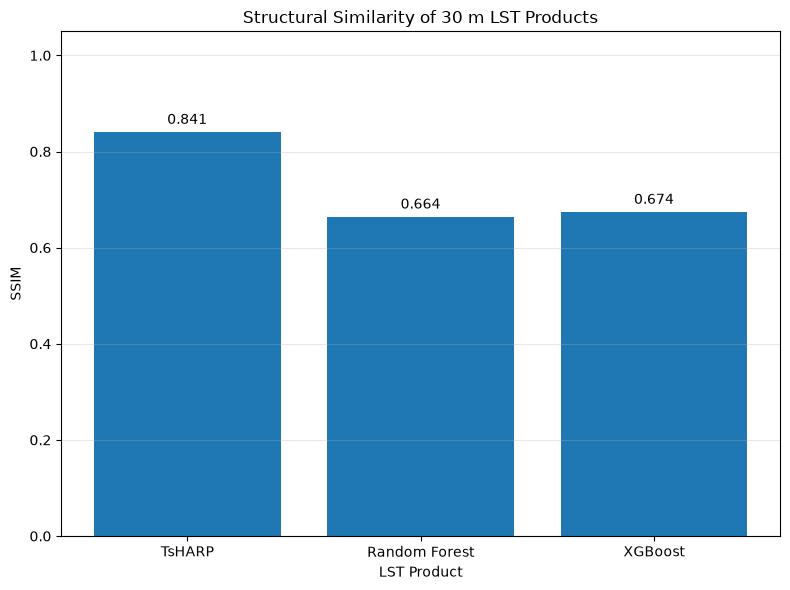

In [207]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

bars = plt.bar(
    structural_results["Model"],
    structural_results["SSIM"]
)

for bar, value in zip(
    bars,
    structural_results["SSIM"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.01,
        f"{value:.3f}",
        ha="center",
        va="bottom"
    )

plt.ylabel("SSIM")
plt.xlabel("LST Product")
plt.title("Structural Similarity of 30 m LST Products")
plt.ylim(0, 1.05)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR/ "Structural_Similarity_30m_LST",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [208]:
from scipy.ndimage import sobel

def gradient_magnitude(image):
    gx = sobel(image, axis=1)
    gy = sobel(image, axis=0)
    return np.sqrt(gx**2 + gy**2)

ref_gradient = gradient_magnitude(ref_struct)
tsharp_gradient = gradient_magnitude(tsharp_struct)
rf_gradient = gradient_magnitude(rf_struct)
xgb_gradient = gradient_magnitude(xgb_struct)

In [209]:
import pandas as pd

gradient_results = pd.DataFrame({
    "Model": [
        "Reference",
        "TsHARP",
        "Random Forest",
        "XGBoost"
    ],
    "Mean_Gradient": [
        np.mean(ref_gradient),
        np.mean(tsharp_gradient),
        np.mean(rf_gradient),
        np.mean(xgb_gradient)
    ]
})

gradient_results = gradient_results.round(4)

display(gradient_results)

gradient_results.to_csv(
    PROJECT_DIR/"results/structural_validation/gradient_results.csv",
    index=False
)

,Model,Mean_Gradient
0,Reference,1.2278
1,TsHARP,1.7120
2,Random Forest,2.4692
3,XGBoost,2.4100


TsHARP most closely preserves the reference's overall spatial structure and thermal-extreme locations, whereas RF and XGBoost produce substantially different fine-scale spatial patterns. Although RF and XGBoost retain reasonable statistical agreement with the reference, their reduced thermal range and altered spatial autocorrelation/variogram structure, together with elevated local gradients, indicate that their fine-scale predictions represent a redistribution of spatial variability rather than a simple reproduction of the reference thermal structure.